# Práctica 03 — Series de Fourier: magnitud y fase

**Bioseñales y Sistemas**

Este notebook desarrolla los puntos **a–k** de la práctica: construcción de señales cuadrada y triangular, cálculo de coeficientes mediante FFT, espectros de magnitud y fase, reconstrucción con un número finito de armónicos, fenómeno de Gibbs y análisis espectral de una señal ECG limpia.

Para no confundir símbolos:
- `M` = número de muestras en un período.
- `K` = máximo orden armónico usado en una reconstrucción.
- `f0` = frecuencia fundamental.


## 1. Importación de librerías y parámetros

Se trabajará con un período completo de las señales. Elegimos:

- Amplitud: \(A=1\)
- Frecuencia fundamental: \(f_0=1\ \text{Hz}\)
- Período: \(T_0=1/f_0=1\ \text{s}\)
- Número de muestras por período: \(M=2000\)

`endpoint=False` evita repetir la muestra de \(t=0\) al final del período.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

A = 1.0
f0 = 1.0
T0 = 1 / f0
M = 2000

t = np.linspace(0, T0, M, endpoint=False)

print(f"Amplitud A = {A}")
print(f"Frecuencia fundamental f0 = {f0} Hz")
print(f"Período T0 = {T0} s")
print(f"Número de muestras M = {M}")


Amplitud A = 1.0
Frecuencia fundamental f0 = 1.0 Hz
Período T0 = 1.0 s
Número de muestras M = 2000


## a) Señal cuadrada periódica

Se construye una onda cuadrada simétrica entre \(-A\) y \(+A\), con ciclo útil del 50 %.


In [2]:
x_cuadrada = np.where((t % T0) < T0/2, A, -A)


## b) Señal triangular periódica

Se utiliza la identidad

\[
x_{\mathrm{tri}}(t)=\frac{2A}{\pi}\arcsin\left[\sin(2\pi f_0t)\right]
\]

que produce una señal triangular entre \(-A\) y \(+A\) con la misma frecuencia fundamental.


In [3]:
x_triangular = (2*A/np.pi) * np.arcsin(np.sin(2*np.pi*f0*t))


## c) Señales en el dominio del tiempo


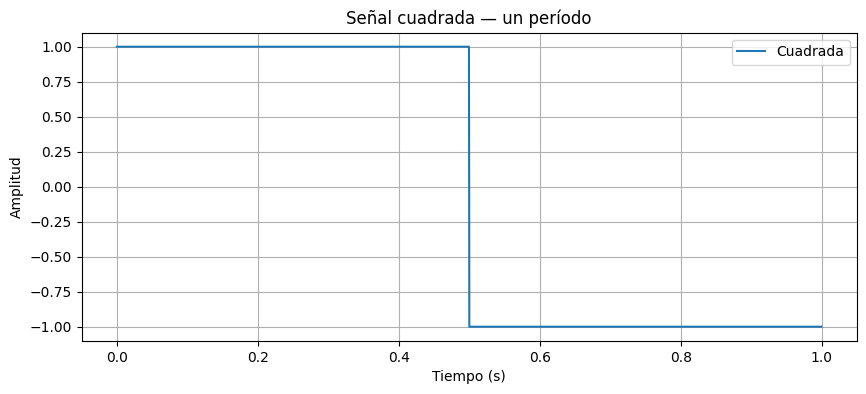

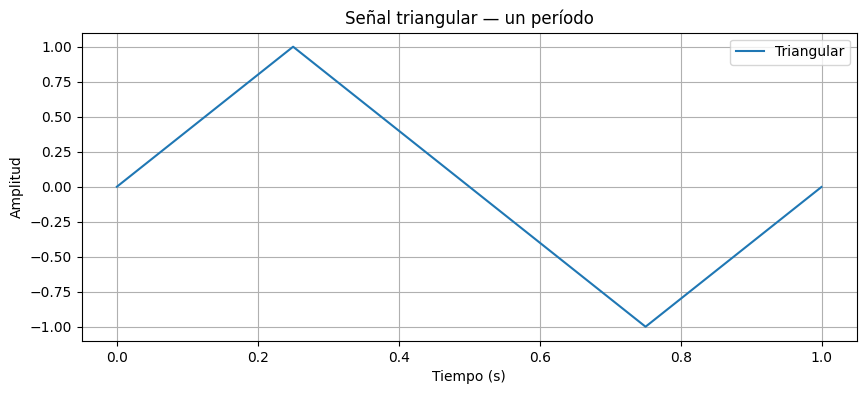

In [4]:
plt.figure(figsize=(10, 4))
plt.plot(t, x_cuadrada, label="Cuadrada")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.title("Señal cuadrada — un período")
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(t, x_triangular, label="Triangular")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.title("Señal triangular — un período")
plt.grid(True)
plt.legend()
plt.show()


## d) Función para obtener los coeficientes de la serie de Fourier

Para \(M\) muestras de un período:

\[
c_k=\frac{1}{M}\sum_{n=0}^{M-1}x[n]e^{-j2\pi kn/M}.
\]

`np.fft.fft(x)` calcula la DFT. Al dividir entre `M`, se obtiene la normalización correspondiente a los coeficientes \(c_k\) de la serie exponencial.


In [5]:
def coeficientes_fourier(x):
    M = len(x)
    return np.fft.fft(x) / M


## e) Coeficientes de las señales cuadrada y triangular


In [6]:
c_cuadrada = coeficientes_fourier(x_cuadrada)
c_triangular = coeficientes_fourier(x_triangular)

print("Primeros 10 coeficientes positivos — señal cuadrada")
for k in range(10):
    print(f"k={k:2d}: c_k = {c_cuadrada[k]: .6f}, |c_k| = {abs(c_cuadrada[k]):.6f}")

print("\nPrimeros 10 coeficientes positivos — señal triangular")
for k in range(10):
    print(f"k={k:2d}: c_k = {c_triangular[k]: .6f}, |c_k| = {abs(c_triangular[k]):.6f}")


Primeros 10 coeficientes positivos — señal cuadrada
k= 0: c_k =  0.000000+0.000000j, |c_k| = 0.000000
k= 1: c_k =  0.001000-0.636619j, |c_k| = 0.636620
k= 2: c_k =  0.000000+0.000000j, |c_k| = 0.000000
k= 3: c_k =  0.001000-0.212205j, |c_k| = 0.212207
k= 4: c_k =  0.000000+0.000000j, |c_k| = 0.000000
k= 5: c_k =  0.001000-0.127321j, |c_k| = 0.127325
k= 6: c_k =  0.000000+0.000000j, |c_k| = 0.000000
k= 7: c_k =  0.001000-0.090942j, |c_k| = 0.090948
k= 8: c_k =  0.000000+0.000000j, |c_k| = 0.000000
k= 9: c_k =  0.001000-0.070731j, |c_k| = 0.070738

Primeros 10 coeficientes positivos — señal triangular
k= 0: c_k =  0.000000+0.000000j, |c_k| = 0.000000
k= 1: c_k = -0.000000-0.405285j, |c_k| = 0.405285
k= 2: c_k = -0.000000-0.000000j, |c_k| = 0.000000
k= 3: c_k =  0.000000+0.045032j, |c_k| = 0.045032
k= 4: c_k = -0.000000+0.000000j, |c_k| = 0.000000
k= 5: c_k = -0.000000-0.016212j, |c_k| = 0.016212
k= 6: c_k =  0.000000-0.000000j, |c_k| = 0.000000
k= 7: c_k = -0.000000+0.008271j, |c_k| = 0.

### Interpretación esperada

**Onda cuadrada:** predominan los armónicos impares \(1,3,5,\dots\). Sus amplitudes disminuyen aproximadamente como \(1/k\). Por eso conserva una cantidad importante de armónicos altos y puede formar cambios muy bruscos.

**Onda triangular:** también predominan los armónicos impares, pero sus amplitudes disminuyen aproximadamente como \(1/k^2\). Los armónicos altos son mucho más pequeños y la señal es más suave.


## f) Función para graficar espectro de magnitud y fase

El espectro se centra con `fftshift` para mostrar armónicos negativos y positivos.

La fase de un coeficiente cuya magnitud es prácticamente cero no tiene interpretación útil; por eso se ocultan fases asociadas a magnitudes numéricamente despreciables.


In [7]:
def graficar_espectros(c, f0, titulo="", max_armonico=30):
    M = len(c)

    c_shift = np.fft.fftshift(c)
    k = np.fft.fftshift(np.fft.fftfreq(M, d=1/M))
    f = k * f0

    magnitud = np.abs(c_shift)
    fase = np.angle(c_shift)

    limite = np.max(magnitud) * 1e-8
    fase_visible = fase.copy()
    fase_visible[magnitud < limite] = np.nan

    mascara = np.abs(k) <= max_armonico

    plt.figure(figsize=(11, 4))
    plt.stem(f[mascara], magnitud[mascara], basefmt=" ")
    plt.xlabel("Frecuencia (Hz)")
    plt.ylabel("|c_k|")
    plt.title(f"Espectro de magnitud — {titulo}")
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(11, 4))
    plt.stem(f[mascara], fase_visible[mascara], basefmt=" ")
    plt.xlabel("Frecuencia (Hz)")
    plt.ylabel("Fase (rad)")
    plt.title(f"Espectro de fase — {titulo}")
    plt.grid(True)
    plt.show()


## g) Espectros de magnitud y fase


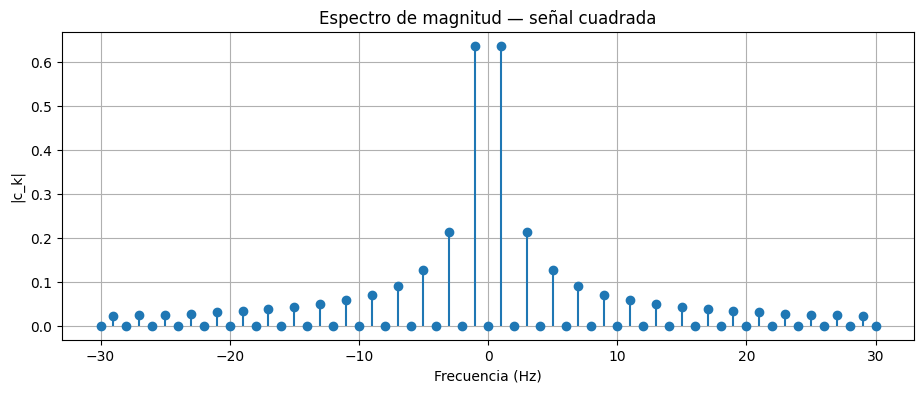

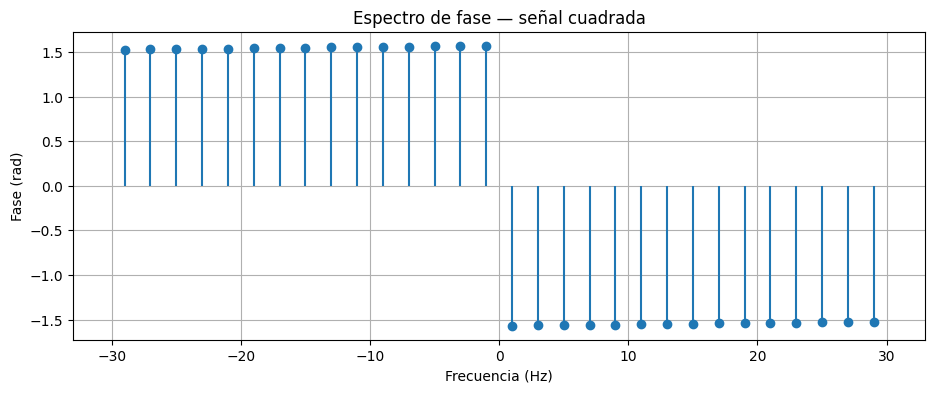

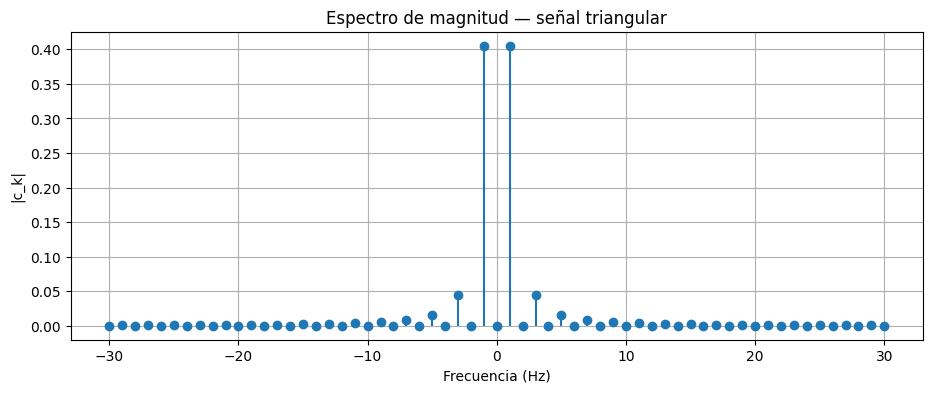

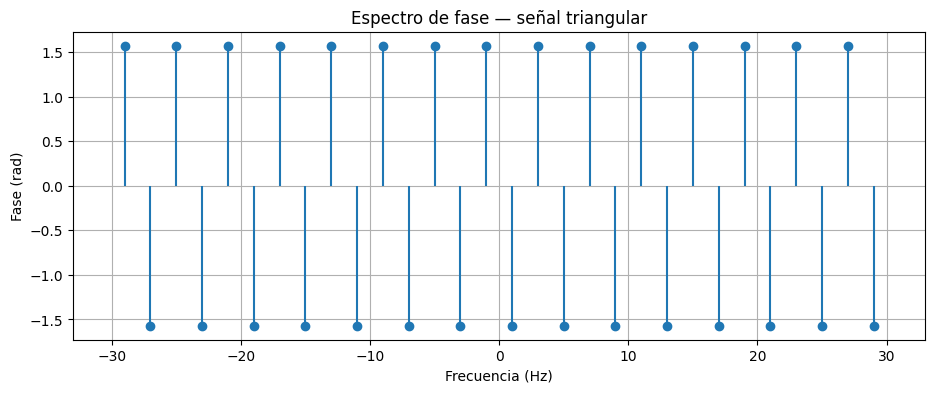

In [8]:
graficar_espectros(c_cuadrada, f0, "señal cuadrada", max_armonico=30)
graficar_espectros(c_triangular, f0, "señal triangular", max_armonico=30)


### Qué debería verse

1. El espectro de una señal real es simétrico en magnitud: \(|c_{-k}|=|c_k|\).
2. La cuadrada presenta armónicos impares que decrecen lentamente.
3. La triangular presenta armónicos impares que decrecen mucho más rápido.
4. Los armónicos pares son nulos o prácticamente nulos.
5. La fase depende del origen temporal escogido para la señal.


## h) Función de reconstrucción con un número finito de armónicos

Para una señal real:

\[
x_K[n]\approx c_0+\sum_{k=1}^{K}
2|c_k|\cos\left(\frac{2\pi kn}{M}+\arg(c_k)\right).
\]

Esta forma es equivalente a sumar los pares de exponenciales complejas de índices \(+k\) y \(-k\).


In [9]:
def reconstruir_fourier(c, K):
    M = len(c)
    n = np.arange(M)

    x_rec = np.real(c[0]) * np.ones(M)

    for k in range(1, K + 1):
        amplitud_k = 2 * np.abs(c[k])
        fase_k = np.angle(c[k])
        x_rec += amplitud_k * np.cos(2*np.pi*k*n/M + fase_k)

    return x_rec


## i) Reconstrucción con K = 1, 3, 5, 20 y 50

Aquí `K` significa **máximo orden armónico** incluido. En la señal cuadrada y triangular, los armónicos pares son prácticamente cero, pero igualmente forman parte del intervalo \(1,\dots,K\).


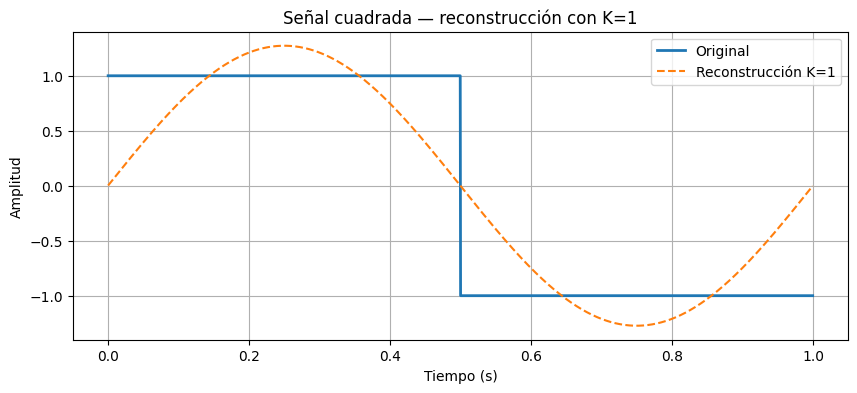

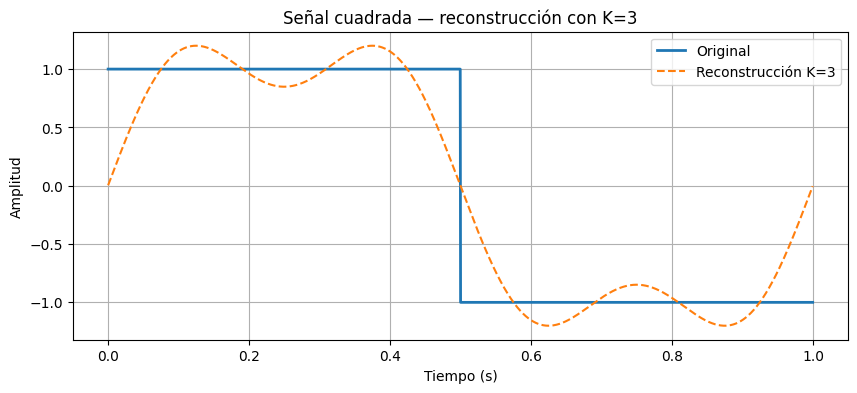

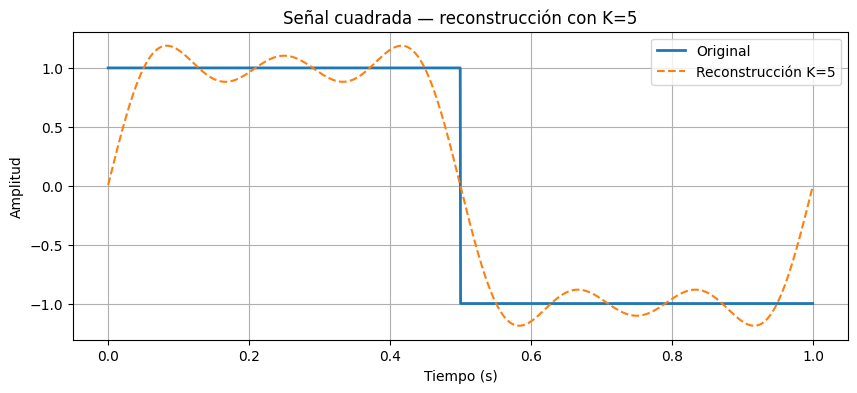

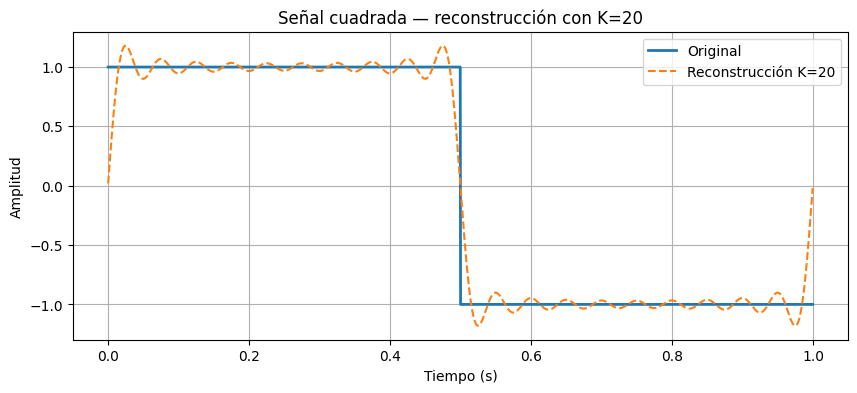

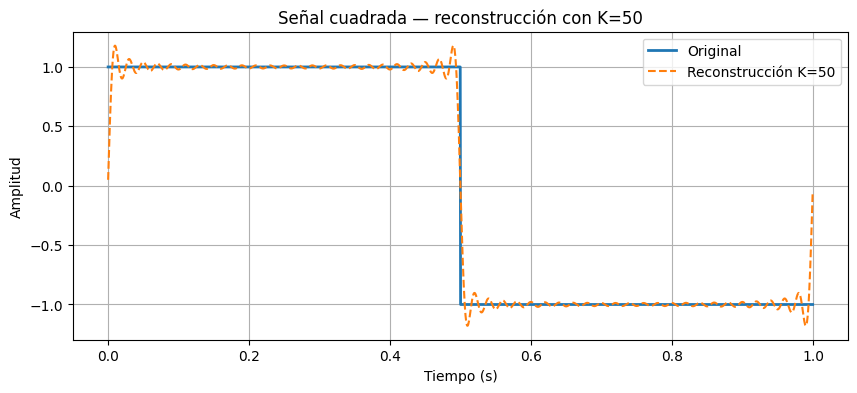

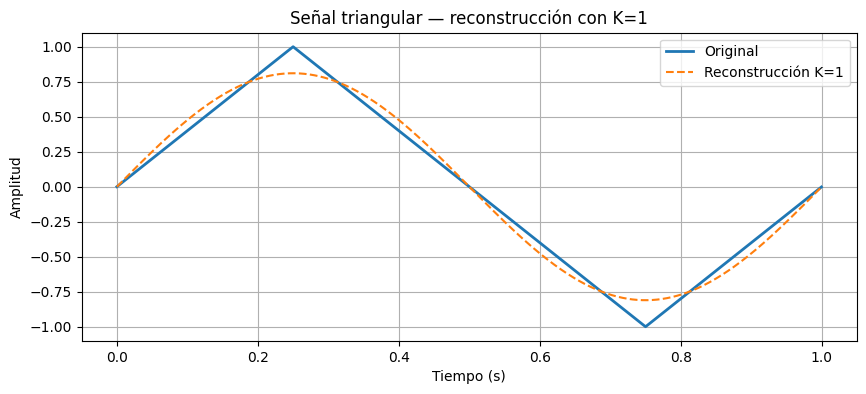

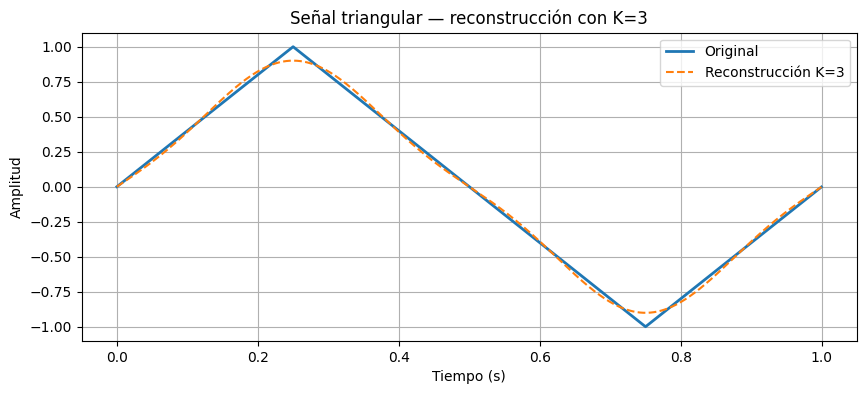

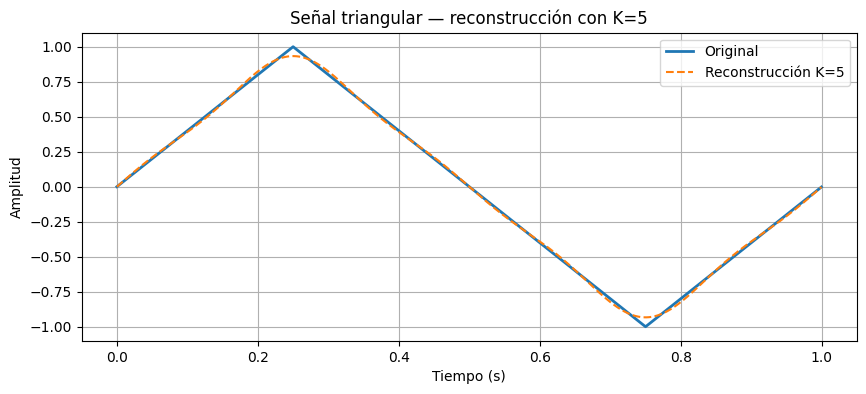

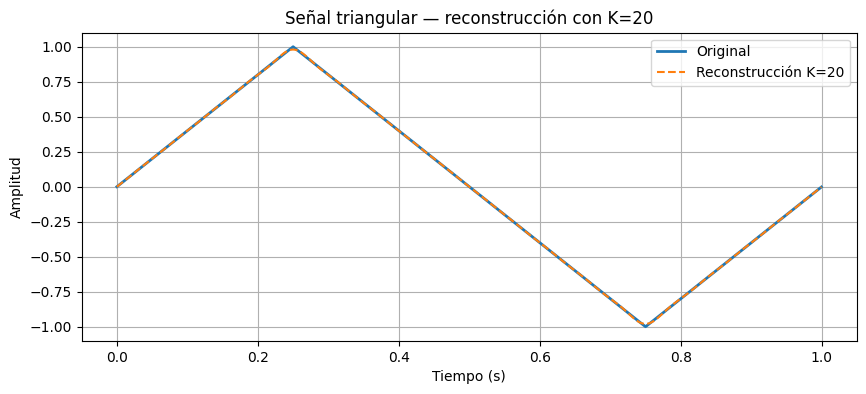

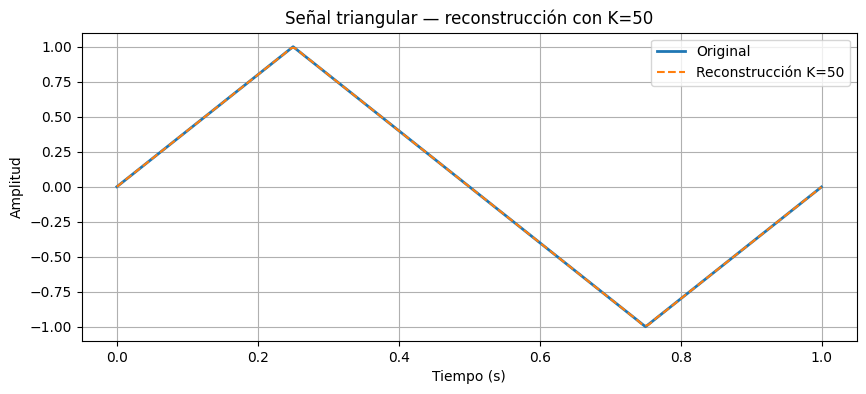

In [10]:
K_valores = [1, 3, 5, 20, 50]

for K in K_valores:
    x_rec = reconstruir_fourier(c_cuadrada, K)

    plt.figure(figsize=(10, 4))
    plt.plot(t, x_cuadrada, label="Original", linewidth=2)
    plt.plot(t, x_rec, "--", label=f"Reconstrucción K={K}")
    plt.xlabel("Tiempo (s)")
    plt.ylabel("Amplitud")
    plt.title(f"Señal cuadrada — reconstrucción con K={K}")
    plt.grid(True)
    plt.legend()
    plt.show()

for K in K_valores:
    x_rec = reconstruir_fourier(c_triangular, K)

    plt.figure(figsize=(10, 4))
    plt.plot(t, x_triangular, label="Original", linewidth=2)
    plt.plot(t, x_rec, "--", label=f"Reconstrucción K={K}")
    plt.xlabel("Tiempo (s)")
    plt.ylabel("Amplitud")
    plt.title(f"Señal triangular — reconstrucción con K={K}")
    plt.grid(True)
    plt.legend()
    plt.show()


## j) Fenómeno de Gibbs

En la onda cuadrada aparecen oscilaciones cerca de cada discontinuidad. Al aumentar `K`:

- la señal se aproxima mejor a la forma cuadrada en las zonas alejadas del salto;
- las oscilaciones se concentran en una región cada vez más estrecha;
- el sobrepico cercano al salto **no desaparece**;
- en el límite, el máximo sobrepico es aproximadamente el **8.95 % de la altura total del salto**.

Para una cuadrada de \(-1\) a \(+1\), el salto vale \(2\), de modo que el sobrepico esperado sobre el nivel \(+1\) es aproximadamente \(0.0895\times 2\approx0.179\), es decir, un pico cercano a \(1.179\).


In [11]:
print("Estimación del sobrepico de Gibbs")
print("K\tmáximo\t\tsobrepico / salto (%)")

salto = 2*A

for K in K_valores:
    x_rec = reconstruir_fourier(c_cuadrada, K)
    maximo = np.max(x_rec)
    porcentaje = 100*(maximo - A)/salto
    print(f"{K}\t{maximo:.6f}\t{porcentaje:.3f}")


Estimación del sobrepico de Gibbs
K	máximo		sobrepico / salto (%)
1	1.273238	13.662
3	1.200419	10.021
5	1.188359	9.418
20	1.179747	8.987
50	1.178696	8.935


### Texto breve para el informe — fenómeno de Gibbs

La reconstrucción de la señal cuadrada mejora a medida que se incluyen más armónicos. Sin embargo, cerca de las discontinuidades se observan oscilaciones y sobrepicos que permanecen aun cuando aumenta el número de armónicos. Este comportamiento corresponde al fenómeno de Gibbs. Al incrementar el orden de la reconstrucción, la zona donde aparecen las oscilaciones se vuelve más estrecha, pero su máximo sobrepico tiende a un valor cercano al 8.95 % de la altura del salto. La señal triangular no presenta el fenómeno con la misma intensidad porque es continua y sus coeficientes de Fourier decrecen más rápidamente.


# k) ECG limpio y composición espectral

Se utilizará el archivo **`ecgsyn.dat`** de **PhysioNet ECGSYN**.

El archivo de ejemplo contiene tres columnas:

1. tiempo en segundos;
2. amplitud ECG en mV;
3. marcador de la onda: 0 = ninguno, 1 = P, 2 = Q, 3 = R, 4 = S, 5 = T.

Se eligió esta señal porque es sintética y, por tanto, resulta adecuada como referencia **sin ruido de adquisición**, conservando una morfología P-QRS-T realista.

**Página:** https://physionet.org/content/ecgsyn/1.0.0/sample-output/ecgsyn.dat  
**Descarga directa:** https://physionet.org/files/ecgsyn/1.0.0/sample-output/ecgsyn.dat?download=

Descarga el archivo `ecgsyn.dat` y súbelo a Colab al ejecutar la siguiente celda.


In [12]:
from google.colab import files

uploaded = files.upload()
nombre_archivo = next(iter(uploaded.keys()))

datos = np.loadtxt(nombre_archivo)

t_ecg = datos[:, 0]
ecg = datos[:, 1]
marcadores = datos[:, 2].astype(int)

fs_ecg = 1 / np.median(np.diff(t_ecg))

print(f"Archivo cargado: {nombre_archivo}")
print(f"Número de muestras: {len(ecg)}")
print(f"Frecuencia de muestreo estimada: {fs_ecg:.2f} Hz")
print(f"Duración: {t_ecg[-1] - t_ecg[0]:.2f} s")


Saving ecgsyn.dat to ecgsyn.dat
Archivo cargado: ecgsyn.dat
Número de muestras: 65772
Frecuencia de muestreo estimada: 256.02 Hz
Duración: 256.92 s


## ECG en el dominio del tiempo

Se muestran los primeros cinco segundos para distinguir varios ciclos P-QRS-T.


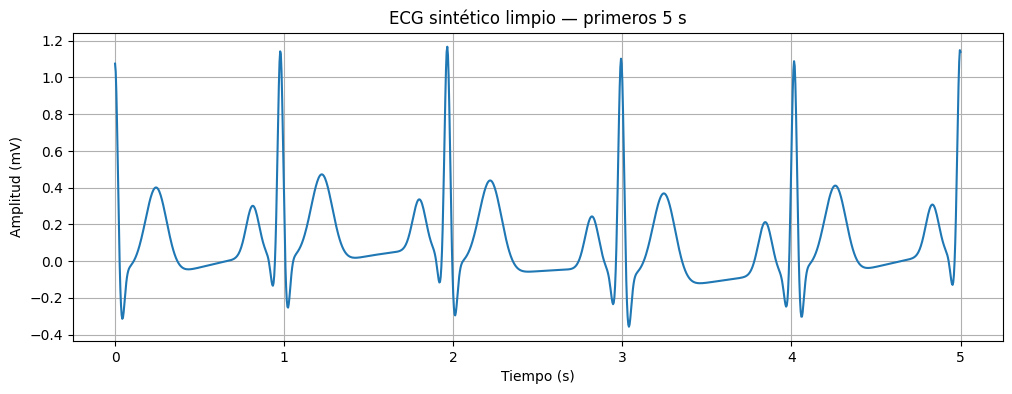

In [13]:
mascara_5s = t_ecg <= (t_ecg[0] + 5)

plt.figure(figsize=(12, 4))
plt.plot(t_ecg[mascara_5s], ecg[mascara_5s])
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud (mV)")
plt.title("ECG sintético limpio — primeros 5 s")
plt.grid(True)
plt.show()


## Frecuencia cardíaca aproximada usando los marcadores R

El código identifica los instantes marcados con `3`, que corresponden a picos R, y calcula el promedio de los intervalos RR.


In [14]:
t_R = t_ecg[marcadores == 3]

if len(t_R) >= 2:
    RR_promedio = np.mean(np.diff(t_R))
    FC_promedio = 60 / RR_promedio
    print(f"Intervalo RR promedio: {RR_promedio:.3f} s")
    print(f"Frecuencia cardíaca promedio: {FC_promedio:.2f} lpm")
    print(f"Frecuencia fundamental cardíaca aproximada: {FC_promedio/60:.3f} Hz")
else:
    print("No se encontraron suficientes marcadores R.")


Intervalo RR promedio: 1.000 s
Frecuencia cardíaca promedio: 60.01 lpm
Frecuencia fundamental cardíaca aproximada: 1.000 Hz


## Composición espectral del ECG

Antes de la FFT se elimina el valor medio. Se utiliza `rfft` porque la señal ECG es real y solo necesitamos el espectro de frecuencias no negativas.

La gráfica se limita a 50 Hz porque allí se encuentra la mayor parte del contenido morfológico de interés para P, QRS y T en un ECG convencional.


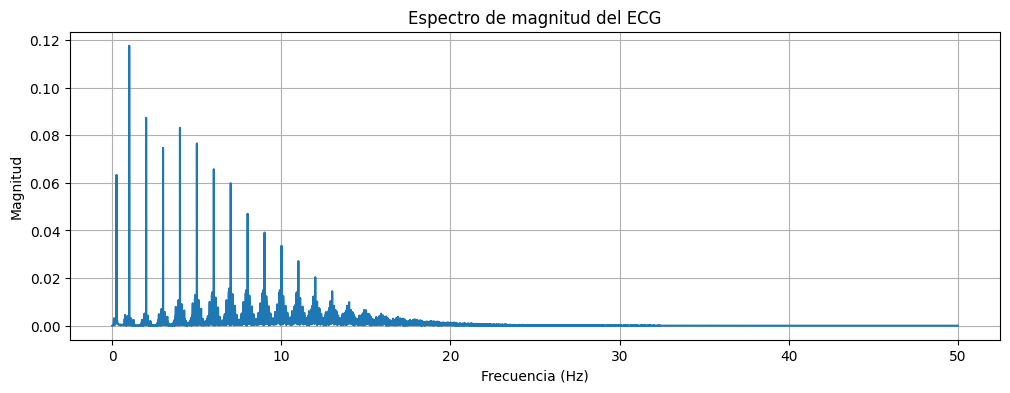

In [15]:
ecg_centrada = ecg - np.mean(ecg)

N_ecg = len(ecg_centrada)
C_ecg = np.fft.rfft(ecg_centrada) / N_ecg
f_ecg = np.fft.rfftfreq(N_ecg, d=1/fs_ecg)

magnitud_ecg = 2*np.abs(C_ecg)
magnitud_ecg[0] = np.abs(C_ecg[0])

mascara_f = f_ecg <= 50

plt.figure(figsize=(12, 4))
plt.plot(f_ecg[mascara_f], magnitud_ecg[mascara_f])
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud")
plt.title("Espectro de magnitud del ECG")
plt.grid(True)
plt.show()


## Interpretación fisiológica del espectro del ECG

Las bandas no son fronteras rígidas y existe superposición entre los componentes.

- **Onda P:** corresponde a la despolarización auricular. Su contenido es relativamente bajo en frecuencia; suele concentrarse principalmente por debajo de unos 10–15 Hz, aunque según el método pueden describirse componentes de aproximadamente 5–30 Hz.
- **Complejo QRS:** representa la despolarización ventricular y presenta los cambios temporales más rápidos. Por eso contiene más energía en frecuencias altas que P y T. Una banda práctica común es aproximadamente 5–25 Hz, con contenido que puede extenderse hacia 40–50 Hz.
- **Onda T:** representa la repolarización ventricular y es más lenta/suave. Su energía se encuentra principalmente en frecuencias bajas, típicamente por debajo de unos 10 Hz.

En el espectro global también pueden aparecer picos cerca de la frecuencia cardíaca fundamental y en sus armónicos, porque el ECG se repite de forma aproximadamente periódica.


## Conclusión breve

Las series de Fourier permiten describir una señal periódica mediante componentes armónicas. La onda cuadrada necesita una cantidad importante de armónicos altos debido a sus discontinuidades, mientras que la onda triangular posee un espectro que decrece con mayor rapidez. El truncamiento de la serie de una onda cuadrada produce el fenómeno de Gibbs: las oscilaciones se estrechan al aumentar el número de armónicos, pero el sobrepico no desaparece.

En el ECG, la composición espectral se relaciona con la rapidez de los cambios morfológicos. Las ondas P y T son relativamente lentas y concentran su contenido en frecuencias bajas, mientras que el complejo QRS, por sus pendientes abruptas, posee contenido de mayor frecuencia. Esto explica por qué los armónicos de orden superior son importantes para representar correctamente los detalles del QRS.


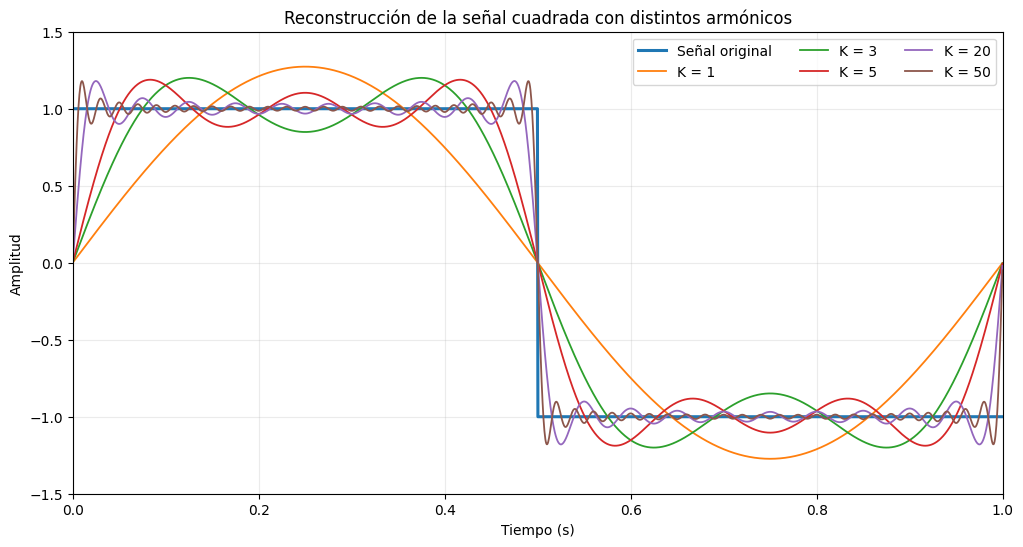

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros de la señal
A = 1.0          # Amplitud
f0 = 1.0         # Frecuencia fundamental (Hz)
T0 = 1 / f0      # Periodo
M = 2000         # Número de muestras

# Vector de tiempo para un periodo
t = np.linspace(0, T0, M, endpoint=False)

# Señal cuadrada original
x_cuadrada = np.where((t % T0) < T0/2, A, -A)

# Coeficientes de Fourier usando FFT
c = np.fft.fft(x_cuadrada) / M


# Función para reconstruir la señal con K armónicos
def reconstruir_fourier(c, K):
    M = len(c)
    n = np.arange(M)

    # Componente DC
    x_rec = np.real(c[0]) * np.ones(M)

    # Suma de los armónicos
    for k in range(1, K + 1):

        amplitud_k = 2 * np.abs(c[k])
        fase_k = np.angle(c[k])

        x_rec += amplitud_k * np.cos(
            2 * np.pi * k * n / M + fase_k
        )

    return x_rec


# Valores de K solicitados en la práctica
K_valores = [1, 3, 5, 20, 50]


# GRÁFICA
plt.figure(figsize=(12, 6))

# Señal original
plt.plot(
    t,
    x_cuadrada,
    linewidth=2.2,
    label="Señal original"
)

# Reconstrucciones
for K in K_valores:

    x_rec = reconstruir_fourier(c, K)

    plt.plot(
        t,
        x_rec,
        linewidth=1.3,
        label=f"K = {K}"
    )


plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")

plt.title(
    "Reconstrucción de la señal cuadrada con distintos armónicos"
)

plt.xlim(0, 1)
plt.ylim(-1.5, 1.5)

plt.grid(True, alpha=0.25)

plt.legend(
    ncol=3
)

plt.show()